<a href="https://colab.research.google.com/github/npenagan-2007/8414_fds/blob/main/.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:

# Experiment5: Data Preprocessing on Iris Dataset

import pandas as pd
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

# 1. Load Iris dataset
df = sns.load_dataset('iris')
print("Original Dataset:")
print(df.head())

# 2. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Handle missing values
df = df.dropna()

# 4. Encode categorical column
le = LabelEncoder()
df['species'] = le.fit_transform(df['species'])
print("\nEncoded Dataset:")
print(df.head())

# 5. Separate features and target
X = df.drop('species', axis=1)
y = df['species']

# 6. Normalization (values between 0 and 1)
minmax = MinMaxScaler()
X_normalized = minmax.fit_transform(X)

print("\nNormalized Data:")
print(pd.DataFrame(X_normalized, columns=X.columns).head())

# 7. Standardization (mean 0, standard deviation 1)
scaler = StandardScaler()
X_standardized = scaler.fit_transform(X)

print("\nStandardized Data:")
print(pd.DataFrame(X_standardized, columns=X.columns).head())

# 8. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining data size:", X_train.shape)
print("Testing data size:", X_test.shape)

print("\nData preprocessing completed successfully!")


Original Dataset:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Encoded Dataset:
   sepal_length  sepal_width  petal_length  petal_width  species
0           5.1          3.5           1.4          0.2        0
1           4.9          3.0           1.4          0.2        0
2           4.7          3.2           1.3          0.2        0
3           4.6          3.1           1.5          0.2        0
4           5.0          3.6           1.4          0.2        0

Normalized Data:
   sepal_length  sepal_width  petal_length  petal_wi

Range: 79.58
Variance: 211.0191247463081
Standard Deviation: 14.526497332334044
Interquartile Range (IQR): 17.875


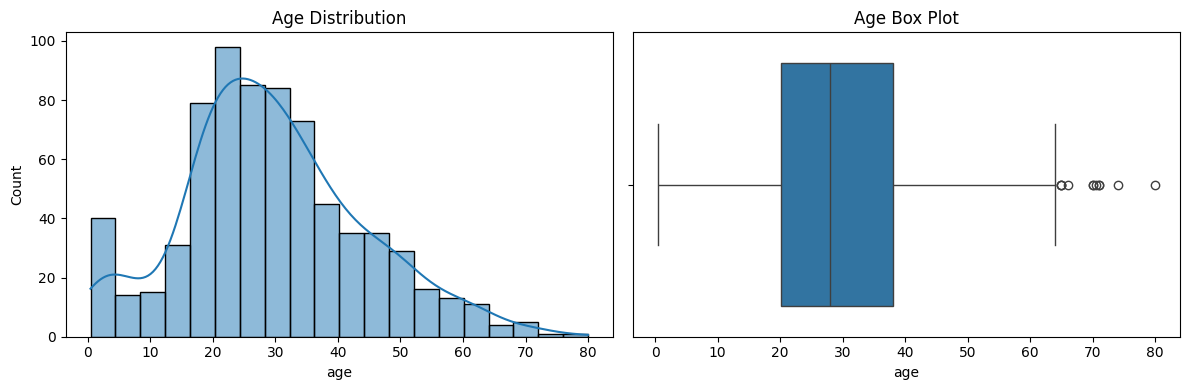

In [1]:
# Experiment 6: Measures of Dispersion and Distribution

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Titanic dataset
df = sns.load_dataset('titanic')

# Select numerical column
data = df['age'].dropna()

# Measures of dispersion
print("Range:", data.max() - data.min())
print("Variance:", data.var())
print("Standard Deviation:", data.std())
print("Interquartile Range (IQR):", data.quantile(0.75) - data.quantile(0.25))

# Distribution plots
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(data, kde=True)
plt.title("Age Distribution")

plt.subplot(1, 2, 2)
sns.boxplot(x=data)
plt.title("Age Box Plot")

plt.tight_layout()
plt.show()

Correlation Matrix:
              sepal_length  sepal_width  petal_length  petal_width
sepal_length      1.000000    -0.117570      0.871754     0.817941
sepal_width      -0.117570     1.000000     -0.428440    -0.366126
petal_length      0.871754    -0.428440      1.000000     0.962865
petal_width       0.817941    -0.366126      0.962865     1.000000


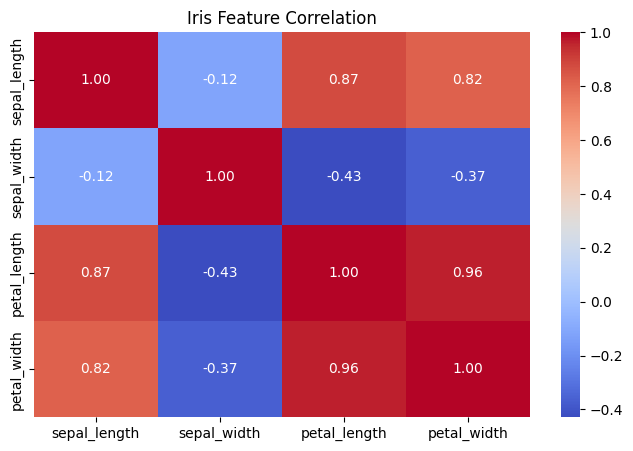

In [2]:
# Experiment 7: Correlation Plot

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Iris dataset
df = sns.load_dataset('iris')

# Select numerical features
features = df.select_dtypes(include='number')

# Calculate correlation
corr = features.corr()

print("Correlation Matrix:")
print(corr)

# Plot heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Iris Feature Correlation")
plt.show()

In [3]:
# Experiment 7: DataFrame Wrangling

import pandas as pd

# Create DataFrames
df1 = pd.DataFrame({
    'ID': [1, 2, 3],
    'Name': ['Asha', 'Ravi', 'Sita']
})

df2 = pd.DataFrame({
    'ID': [1, 2, 3],
    'Marks': [85, 90, 88]
})

# Merge
print("MERGE:")
print(pd.merge(df1, df2, on='ID'))

# Concatenate
print("\nCONCATENATE:")
print(pd.concat([df1, df2], axis=0, ignore_index=True))

# Join using ID as index
print("\nJOIN:")
print(df1.set_index('ID').join(df2.set_index('ID'),
                                lsuffix='_left',
                                rsuffix='_right'))

MERGE:
   ID  Name  Marks
0   1  Asha     85
1   2  Ravi     90
2   3  Sita     88

CONCATENATE:
   ID  Name  Marks
0   1  Asha    NaN
1   2  Ravi    NaN
2   3  Sita    NaN
3   1   NaN   85.0
4   2   NaN   90.0
5   3   NaN   88.0

JOIN:
    Name  Marks
ID             
1   Asha     85
2   Ravi     90
3   Sita     88


In [4]:
# Experiment 8: Data Cleaning

import pandas as pd
import seaborn as sns

# Load dataset
df = sns.load_dataset('titanic')

# Display missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing age with median
df['age'] = df['age'].fillna(df['age'].median())

# Fill missing embarked values with mode
df['embarked'] = df['embarked'].fillna(
    df['embarked'].mode()[0]
)

# Fill missing embark_town values with mode
df['embark_town'] = df['embark_town'].fillna(
    df['embark_town'].mode()[0]
)

# Drop columns with many missing values
df = df.drop(columns=['deck'])

# Remove duplicate rows
df = df.drop_duplicates()

# Display missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned dataset:")
print(df.head())

Missing values before cleaning:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Missing values after cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

Cleaned dataset:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S

In [5]:
# Experiment 9: Advanced DataFrame Wrangling

import pandas as pd

# Create DataFrame
df = pd.DataFrame({
    'Department': ['CSE', 'CSE', 'ECE', 'ECE'],
    'Year': [2, 3, 2, 3],
    'Name': ['Asha', 'Ravi', 'Sita', 'Ram'],
    'Marks': [85, 90, 88, 92]
})

print("Original DataFrame:")
print(df)

# Hierarchical indexing
print("\nHierarchical Indexing:")
multi = df.set_index(['Department', 'Year'])
print(multi)

# Combining DataFrames
df1 = pd.DataFrame({'ID': [1, 2], 'Name': ['Asha', 'Ravi']})
df2 = pd.DataFrame({'ID': [3, 4], 'Name': ['Sita', 'Ram']})

print("\nCombining:")
print(pd.concat([df1, df2], ignore_index=True))

# Merging DataFrames
marks = pd.DataFrame({
    'ID': [1, 2],
    'Marks': [85, 90]
})

students = pd.DataFrame({
    'ID': [1, 2],
    'Name': ['Asha', 'Ravi']
})

print("\nMerging:")
print(pd.merge(students, marks, on='ID'))

# Reshaping using melt
print("\nReshaping:")
print(pd.melt(df, id_vars=['Name'],
              value_vars=['Department', 'Marks']))

# Pivot table
print("\nPivot Table:")
print(df.pivot_table(index='Department',
                     columns='Year',
                     values='Marks'))

Original DataFrame:
  Department  Year  Name  Marks
0        CSE     2  Asha     85
1        CSE     3  Ravi     90
2        ECE     2  Sita     88
3        ECE     3   Ram     92

Hierarchical Indexing:
                 Name  Marks
Department Year             
CSE        2     Asha     85
           3     Ravi     90
ECE        2     Sita     88
           3      Ram     92

Combining:
   ID  Name
0   1  Asha
1   2  Ravi
2   3  Sita
3   4   Ram

Merging:
   ID  Name  Marks
0   1  Asha     85
1   2  Ravi     90

Reshaping:
   Name    variable value
0  Asha  Department   CSE
1  Ravi  Department   CSE
2  Sita  Department   ECE
3   Ram  Department   ECE
4  Asha       Marks    85
5  Ravi       Marks    90
6  Sita       Marks    88
7   Ram       Marks    92

Pivot Table:
Year           2     3
Department            
CSE         85.0  90.0
ECE         88.0  92.0


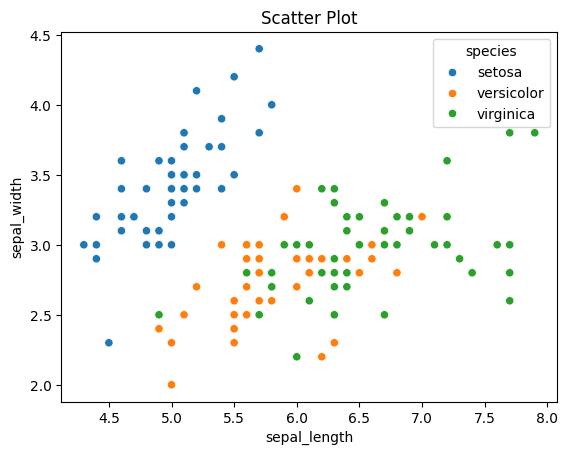

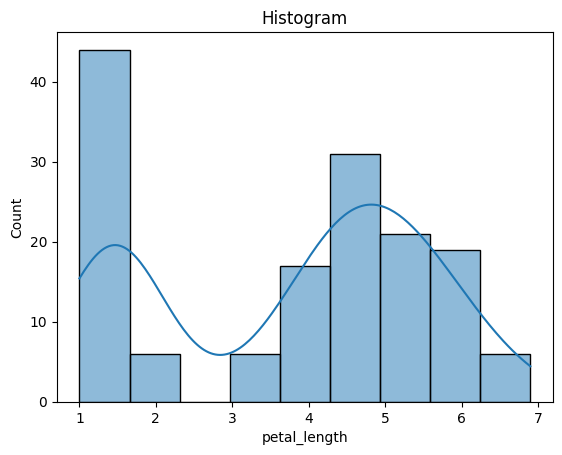

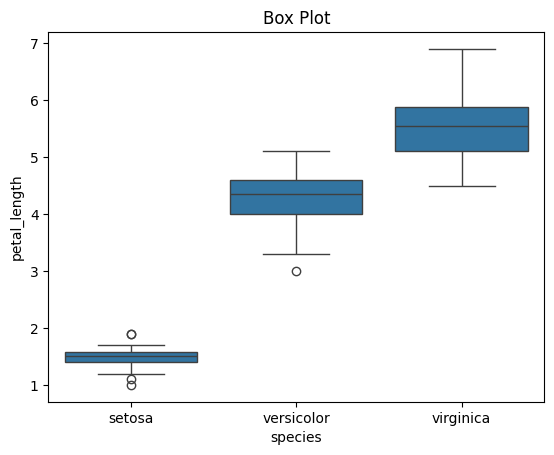

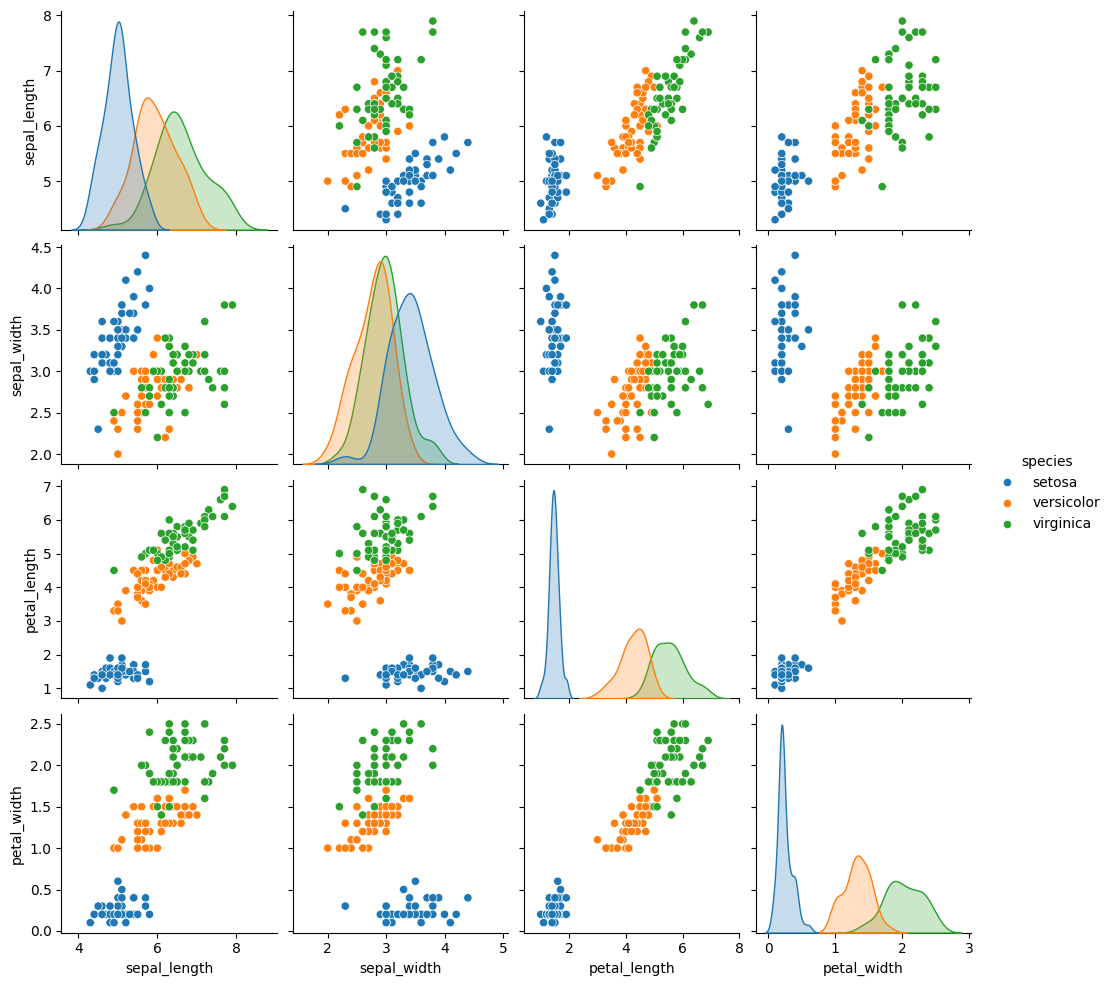

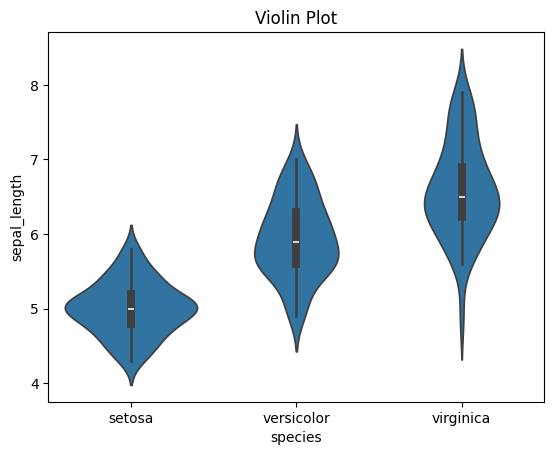

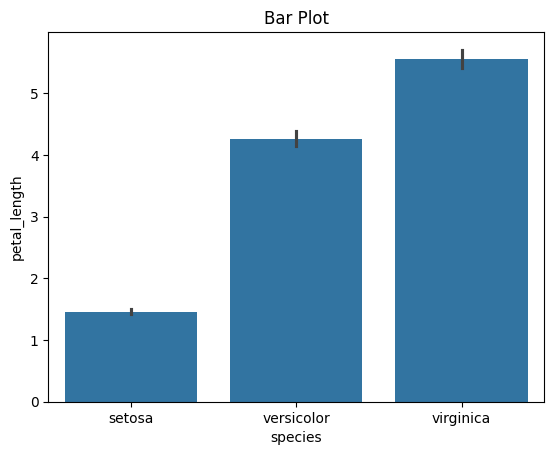

In [6]:
# Experiment 10: Iris Data Visualization

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Iris dataset
df = sns.load_dataset('iris')

# 1. Scatter plot
sns.scatterplot(data=df, x='sepal_length',
                y='sepal_width', hue='species')
plt.title("Scatter Plot")
plt.show()

# 2. Histogram
sns.histplot(data=df, x='petal_length', kde=True)
plt.title("Histogram")
plt.show()

# 3. Box plot
sns.boxplot(data=df, x='species', y='petal_length')
plt.title("Box Plot")
plt.show()

# 4. Pair plot
sns.pairplot(df, hue='species')
plt.show()

# 5. Violin plot
sns.violinplot(data=df, x='species', y='sepal_length')
plt.title("Violin Plot")
plt.show()

# 6. Bar plot
sns.barplot(data=df, x='species', y='petal_length')
plt.title("Bar Plot")
plt.show()